## Load Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, 
classification_report, roc_curve, roc_auc_score)
from imblearn.over_sampling import SMOTE
import shap
import joblib
import warnings
warnings.filterwarnings('ignore')

## Setup

In [2]:
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

## Exploratory Data Analysis

In [3]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
column_names = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation',
                'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

df = pd.read_csv(url, names= column_names, header= None, skipinitialspace= True)
df

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [4]:
print(f'Dataset Shape: {df.shape}')
print(f'\nFirst few rows:')
print(df.head())
print(f'\nData Types: ')
print(df.dtypes)
print(f'\nMissing Values: ')
print(df.isnull().sum())

Dataset Shape: (32561, 15)

First few rows:
   age         workclass  fnlwgt  education  education_num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital_status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital_gain  capital_loss  hours_per_week native_country income  
0          2174             0              40  United-States  <=50K 

Class Distribution: 
income
<=50K    24720
>50K      7841
Name: count, dtype: int64
Imbalance Ratio: 3.15:1


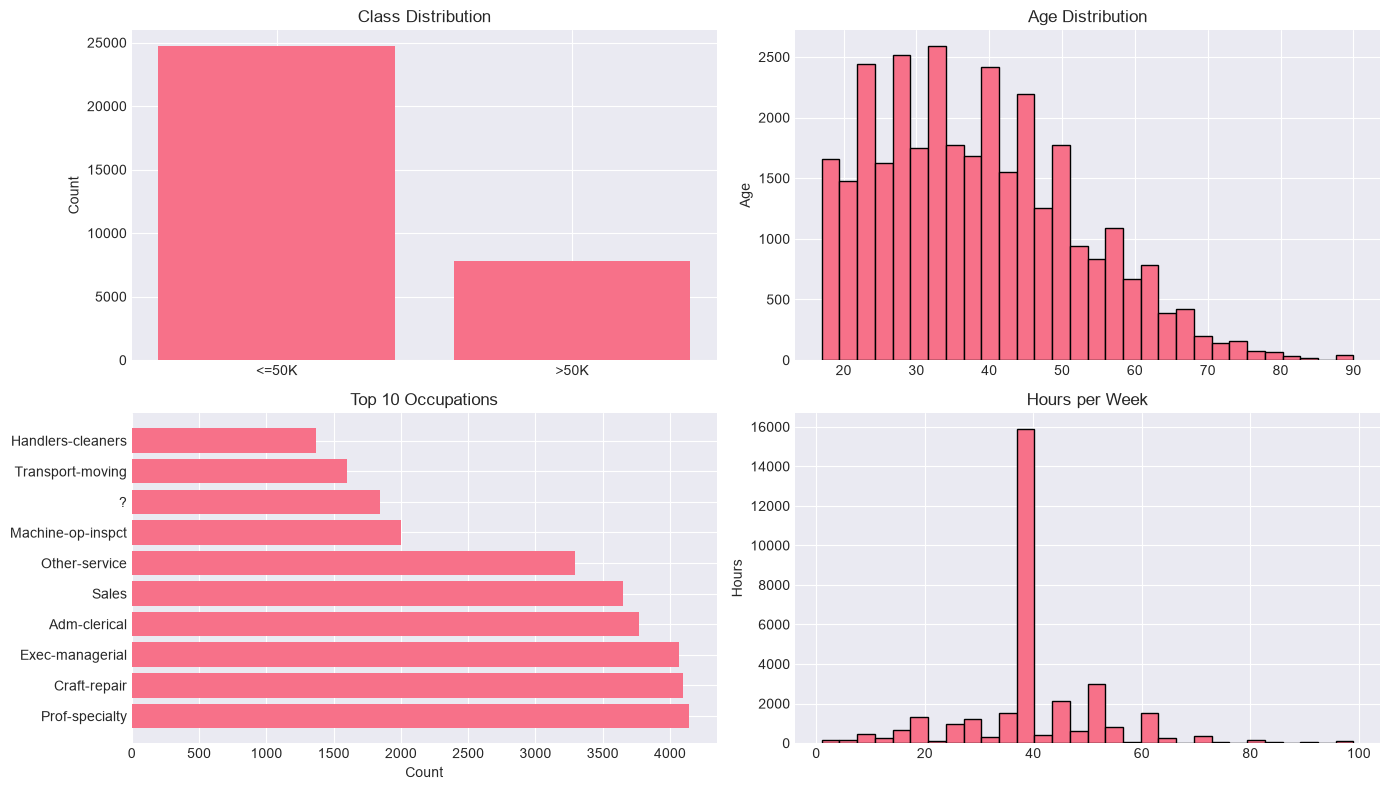

In [5]:
# Exploratory Data Analysis
fig, axes = plt.subplots(2, 2, figsize = (14,8))

# Class Distribution
class_counts = df['income'].value_counts()
axes[0,0].bar(class_counts.index, class_counts.values)
axes[0,0].set_title('Class Distribution')
axes[0,0].set_ylabel('Count')
print(f"Class Distribution: \n{class_counts}")
print(f"Imbalance Ratio: {class_counts.iloc[0]/class_counts.iloc[1]:.2f}:1")

# Age Distribution
axes[0,1].hist(df['age'], bins = 30, edgecolor = 'black')
axes[0,1].set_title('Age Distribution')
axes[0,1].set_ylabel('Age')

# Top Occupations
top_occupations = df['occupation'].value_counts().head(10)
axes[1,0].barh(range(len(top_occupations)), top_occupations.values)
axes[1,0].set_yticks(range(len(top_occupations)))
axes[1,0].set_yticklabels(top_occupations.index)
axes[1,0].set_xlabel('Count')
axes[1,0].set_title('Top 10 Occupations')

# Hours per week
axes[1,1].hist(df['hours_per_week'], bins = 30, edgecolor = 'black')
axes[1,1].set_title('Hours per Week')
axes[1,1].set_ylabel('Hours')

plt.tight_layout()
plt.show()

## Data Preprocessing and Feature Engineering

In [6]:
# Preprocessing pipeline

# 1. Handling missing values (marked as ?)
df_clean = df.replace('?', np.nan)
df_clean = df_clean.dropna()
print(f"Shape after removing missing values: {df_clean.shape}")

# 2. Separate features and targets
y = (df_clean['income'] == '>50K').astype(int)
X = df_clean.drop('income', axis = 1)

# 3. identify numerical and categorical columns
numerical_cols = X.select_dtypes(include= [np.number]).columns.tolist()
categorical_cols = X.select_dtypes(include= ['object']).columns.tolist()

print(f'\nNumerical columns: {numerical_cols}')
print(f'Categorical columns: {categorical_cols}')

# 4. Encoding categorical variables
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le

print(f'\nEncoded features shape: {X.shape}')

Shape after removing missing values: (30162, 15)

Numerical columns: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Encoded features shape: (30162, 14)


In [7]:
# 5. Train-Validation-Test Split
# First split: 70% train, 30% temp

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size= 0.3, random_state= 42, stratify= y)

# Second split: 50% Validation, 50% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size= 0.5, random_state= 42, stratify= y_temp)

print(f"Train set: {X_train.shape}")
print(f"Validation set: {X_val.shape}")
print(f"Test set: {X_test.shape}")

# 6. Scale numerical features
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_val[numerical_cols] = scaler.transform(X_val[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print(f"\nPreprocessing complete!")

Train set: (21113, 14)
Validation set: (4524, 14)
Test set: (4525, 14)

Preprocessing complete!


## Train Multiple Classifiers

In [8]:
# Train Logistic Regression
print('Training Logistic Regression.....')

lr_model = LogisticRegression(max_iter= 1000, random_state= 42, class_weight= 'balanced')
lr_model.fit(X_train, y_train)

# Predictions
y_lr_predict = lr_model.predict(X_val)
y_lr_proba = lr_model.predict_proba(X_val)[:,1]

# Metrics
lr_metrics = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_val, y_lr_predict),
    'Precision': precision_score(y_val, y_lr_predict),
    'Recall': recall_score(y_val, y_lr_predict),
    'F1-Score': f1_score(y_val, y_lr_predict),
    'ROC-AUC': roc_auc_score(y_val, y_lr_proba)
}

print(f'Logistic Regression Metrics: {lr_metrics}')

Training Logistic Regression.....
Logistic Regression Metrics: {'Model': 'Logistic Regression', 'Accuracy': 0.7729885057471264, 'Precision': 0.530349478847333, 'Recall': 0.7682060390763765, 'F1-Score': 0.627493652520856, 'ROC-AUC': 0.8522380733834655}


In [9]:
# Train Random Forest
print("Training Random Forest....")

rf_model = RandomForestClassifier(n_estimators= 100, max_depth= 15, class_weight= 'balanced', random_state= 42, n_jobs= -1)
rf_model.fit(X_train, y_train)

# Predictions
y_rf_pred = rf_model.predict(X_val)
y_rf_proba = rf_model.predict_proba(X_val)[:,1]

# Metrics
rf_metrics = {
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_val, y_rf_pred),
    'Precision': precision_score(y_val, y_rf_pred),
    'Recall': recall_score(y_val, y_rf_pred),
    'F1-Score': f1_score(y_val, y_rf_pred),
    'ROC-AUC': roc_auc_score(y_val, y_rf_proba)
}

print(f"Random Forest Metrics: {rf_metrics}")

Training Random Forest....
Random Forest Metrics: {'Model': 'Random Forest', 'Accuracy': 0.8152077807250221, 'Precision': 0.5899503722084367, 'Recall': 0.844582593250444, 'F1-Score': 0.6946676406135865, 'ROC-AUC': 0.9148054387859539}


In [10]:
# Train XGBoost
print("Training XGBoost....")

xgb_model = XGBClassifier(max_depth = 6, learning_rate = 0.1, n_estimators = 100, scale_pos_weight = 3, random_state = 42, n_jobs = -1, 
                          verbosity = 0)
xgb_model.fit(X_train, y_train)

# Predictions
y_xgb_pred = xgb_model.predict(X_val)
y_xgb_proba = xgb_model.predict_proba(X_val)[:,1]

# Metrics
xgb_metrics = {
    'Model': 'XGBoost',
    'Accuracy': accuracy_score(y_val, y_xgb_pred),
    'Precision': precision_score(y_val, y_xgb_pred),
    'Recall': recall_score(y_val, y_xgb_pred),
    'F1-Score': f1_score(y_val, y_xgb_pred),
    'ROC-AUC': roc_auc_score(y_val, y_xgb_proba)
}

print(f"XGBoost Metrics: {xgb_metrics}")

Training XGBoost....
XGBoost Metrics: {'Model': 'XGBoost', 'Accuracy': 0.8284703801945181, 'Precision': 0.6091022443890274, 'Recall': 0.8676731793960923, 'F1-Score': 0.7157509157509158, 'ROC-AUC': 0.9248178585878016}


## Model Comparison

In [11]:
# Model Comparison
comparison_df = pd.DataFrame([lr_metrics, rf_metrics, xgb_metrics])
print("\n=== Model Comparison ===")
print(comparison_df.to_string(index= False))
print(f"\nBest Model (F1-Score): {comparison_df.loc[comparison_df['F1-Score'].idxmax(), 'Model']}")


=== Model Comparison ===
              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression  0.772989   0.530349 0.768206  0.627494 0.852238
      Random Forest  0.815208   0.589950 0.844583  0.694668 0.914805
            XGBoost  0.828470   0.609102 0.867673  0.715751 0.924818

Best Model (F1-Score): XGBoost


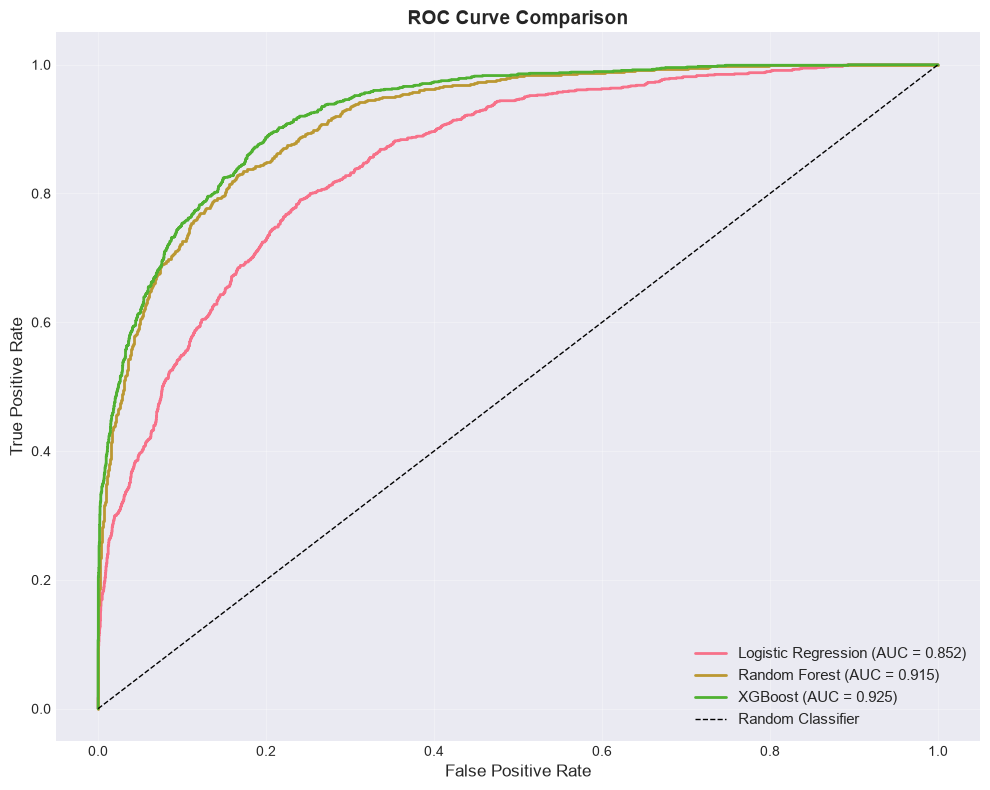

In [12]:
# ROC Curves Comparison
plt.figure(figsize=(10,8))

fpr_lr, tpr_lr, _ = roc_curve(y_val, y_lr_proba)
fpr_rf, tpr_rf, _ = roc_curve(y_val, y_rf_proba)
fpr_xgb, tpr_xgb, _ = roc_curve(y_val, y_xgb_proba)

plt.plot(fpr_lr, tpr_lr, label = f'Logistic Regression (AUC = {lr_metrics["ROC-AUC"]:.3f})', linewidth = 2)
plt.plot(fpr_rf, tpr_rf, label = f'Random Forest (AUC = {rf_metrics["ROC-AUC"]:.3f})', linewidth = 2)
plt.plot(fpr_xgb, tpr_xgb, label = f'XGBoost (AUC = {xgb_metrics["ROC-AUC"]:.3f})', linewidth = 2)
plt.plot([0,1],[0,1], 'k--', label = 'Random Classifier', linewidth = 1)

plt.xlabel('False Positive Rate', fontsize = 12)
plt.ylabel('True Positive Rate', fontsize = 12)
plt.title('ROC Curve Comparison', fontsize = 14, fontweight = 'bold')
plt.legend(fontsize = 11)
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

## Model Interretability with SHAP

In [13]:
# Use best model (XGBoost) for SHAP analysis
# Create SHAP explainer
print("Creating SHAP explainer for XGBoost.....")
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values (use samples for faster computation)
X_val_sample = X_val.sample(min(100, len(X_val)), random_state= 42)
shap_values = explainer.shap_values(X_val_sample)

print("SHAP values calculated!")
print(f'SHAP values shape: {shap_values.shape}')

Creating SHAP explainer for XGBoost.....
SHAP values calculated!
SHAP values shape: (100, 14)


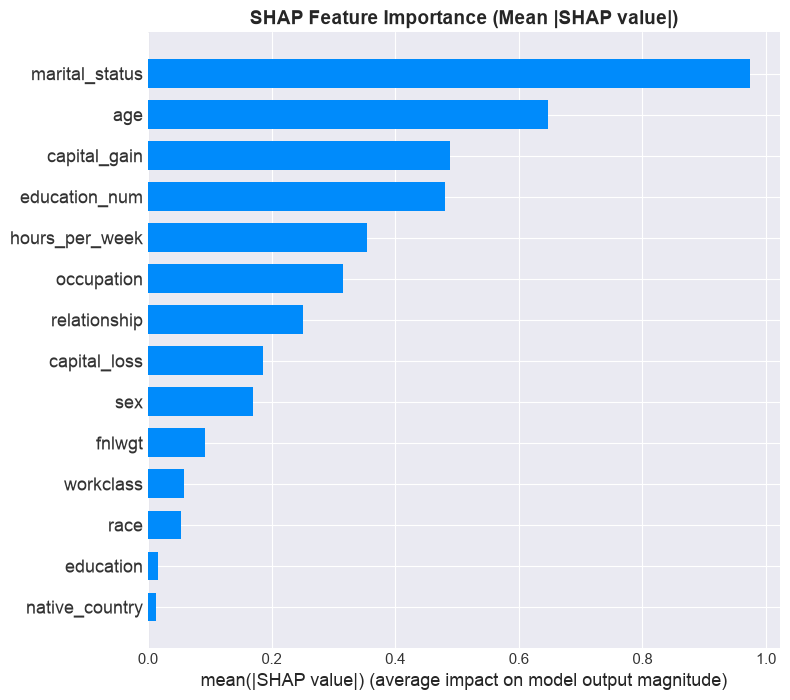


=== Feature Importance from SHAP ===
Higher mean |SHAP value| = more important feature


In [14]:
# SHAP summary plot (Bar)
plt.figure(figsize = (10,8))
shap.summary_plot(shap_values, X_val_sample, plot_type = 'bar', show = False)
plt.title("SHAP Feature Importance (Mean |SHAP value|)", fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

print("\n=== Feature Importance from SHAP ===")
print("Higher mean |SHAP value| = more important feature")

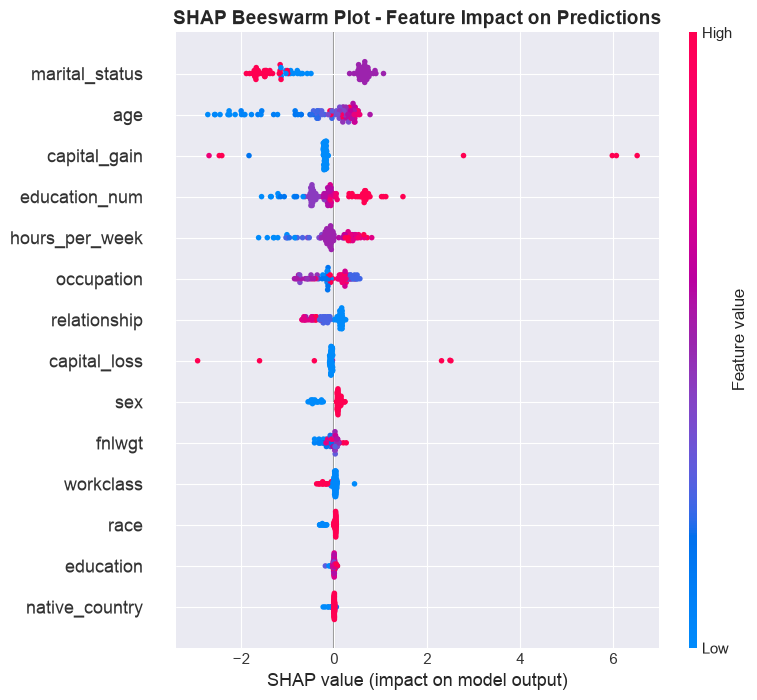

In [15]:
# SHAP summary plot (Beeswarm)
plt.figure(figsize = (10,8))
shap.summary_plot(shap_values, X_val_sample, show = False)
plt.title("SHAP Beeswarm Plot - Feature Impact on Predictions", fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

In [16]:
# SHAP Force Plot for individual prediction
# Show explanation for first positive prediction
positive_idx = np.where(xgb_model.predict(X_val_sample) == 1)[0][0]
print(f"Explaining prediction #{positive_idx}")
print(f"Predicted Class: {xgb_model.predict(X_val_sample)[positive_idx]}")
print(f"Prediction probability: {xgb_model.predict_proba(X_val_sample)[positive_idx]}")

# Note: Force-plot displays best in notebook
shap.force_plot(explainer.expected_value, shap_values[positive_idx], X_val_sample.iloc[positive_idx], show = False)

Explaining prediction #0
Predicted Class: 1
Prediction probability: [0.27038217 0.72961783]


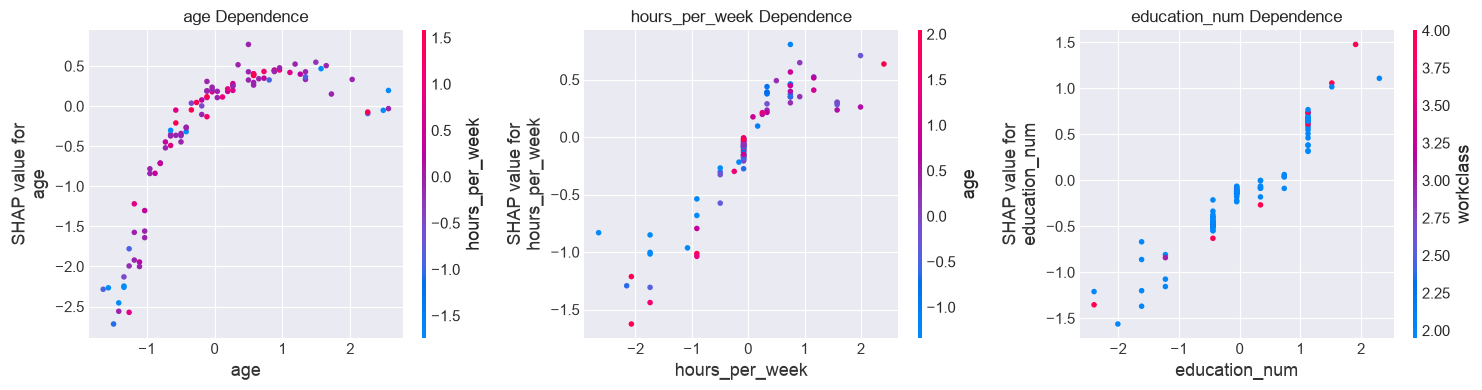


=== SHAP Insights ===
Dependence plots show how model output changes with feature value
Color indicates corelation with another feature


In [17]:
# SHAP Dependence plots for top features
fig, axes = plt.subplots(1,3, figsize = (15,4))

# Get top 3 features
top_features = ['age', 'hours_per_week', 'education_num']
for idx, feature in enumerate(top_features):
    try:
        feature_idx = X_val_sample.columns.get_loc(feature)
        shap.dependence_plot(feature_idx, shap_values, X_val_sample, show = False, ax = axes[idx])
        axes[idx].set_title(f'{feature} Dependence')
    except:
        pass

plt.tight_layout()
plt.show()

print('\n=== SHAP Insights ===')
print('Dependence plots show how model output changes with feature value')
print('Color indicates corelation with another feature')

## Handle Class Imbalance

In [18]:
# Quantify Imbalance
print("=== Class Imbalance Analysis ===")
print(f'Training set class distribution:')
print(y_train.value_counts())
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f'\nImbalance Ratio: {imbalance_ratio:.2f}:1')
print(f'Minority class ({(y_train == 1).sum()} samples)is very severly underrepresented')

=== Class Imbalance Analysis ===
Training set class distribution:
income
0    15857
1     5256
Name: count, dtype: int64

Imbalance Ratio: 3.02:1
Minority class (5256 samples)is very severly underrepresented


In [19]:
# Apply SMOTE
print("\nApplying SMOTE (Synthetic Minority Over-Sampling)....")
smote = SMOTE(random_state= 42, k_neighbors= 5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f'Original training set shape:{X_train.shape}')
print(f'SMOTE training set shape: {X_train_smote.shape}')
print(f'\nNew class Distribution:')
print(pd.Series(y_train_smote).value_counts())


Applying SMOTE (Synthetic Minority Over-Sampling)....
Original training set shape:(21113, 14)
SMOTE training set shape: (31714, 14)

New class Distribution:
income
0    15857
1    15857
Name: count, dtype: int64


In [20]:
# Train XGBoost with SMOTE
print('Training XGBoost with SMOTE....')

xgb_smote = XGBClassifier(max_depth = 6, learning_rate = 0.1, n_estimators = 100, random_state = 42, n_jobs = -1, verbosity = 0)
xgb_smote.fit(X_train_smote, y_train_smote)

y_xgb_smote_pred = xgb_smote.predict(X_val)
y_xgb_smote_proba = xgb_smote.predict_proba(X_val)[:,1]

xgb_smote_metrics = {
    'Model': 'XGBoost with SMOTE',
    'Accuracy': accuracy_score(y_val, y_xgb_smote_pred),
    'Precision': precision_score(y_val, y_xgb_smote_pred),
    'Recall': recall_score(y_val, y_xgb_smote_pred),
    'F1-Score': f1_score(y_val, y_xgb_smote_pred),
    'ROC-AUC': roc_auc_score(y_val, y_xgb_smote_proba)
}

print(f'\nXGBoost with SMOTE metrics: {xgb_smote_metrics}')

Training XGBoost with SMOTE....

XGBoost with SMOTE metrics: {'Model': 'XGBoost with SMOTE', 'Accuracy': 0.8430592396109637, 'Precision': 0.6489971346704871, 'Recall': 0.8046181172291297, 'F1-Score': 0.71847739888977, 'ROC-AUC': 0.9187655574222429}


In [21]:
# Comparison Before vs After Imbalance handling
print("\n=== Imbalance Handling Comparison ===")
comparison_imbalance = pd.DataFrame([xgb_metrics, xgb_smote_metrics])
print(comparison_imbalance.to_string(index= False))

print('\nKey Observations:')
print(f'Recall improvement: {(xgb_smote_metrics['Recall'] - xgb_metrics['Recall']) * 100:.2f}%')
print(f'Precision change: {(xgb_smote_metrics['Precision'] - xgb_metrics['Precision']) * 100:.2f}%')
print(f'SMOTE improves ability to catch minority class (higher recall)')


=== Imbalance Handling Comparison ===
             Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
           XGBoost  0.828470   0.609102 0.867673  0.715751 0.924818
XGBoost with SMOTE  0.843059   0.648997 0.804618  0.718477 0.918766

Key Observations:
Recall improvement: -6.31%
Precision change: 3.99%
SMOTE improves ability to catch minority class (higher recall)


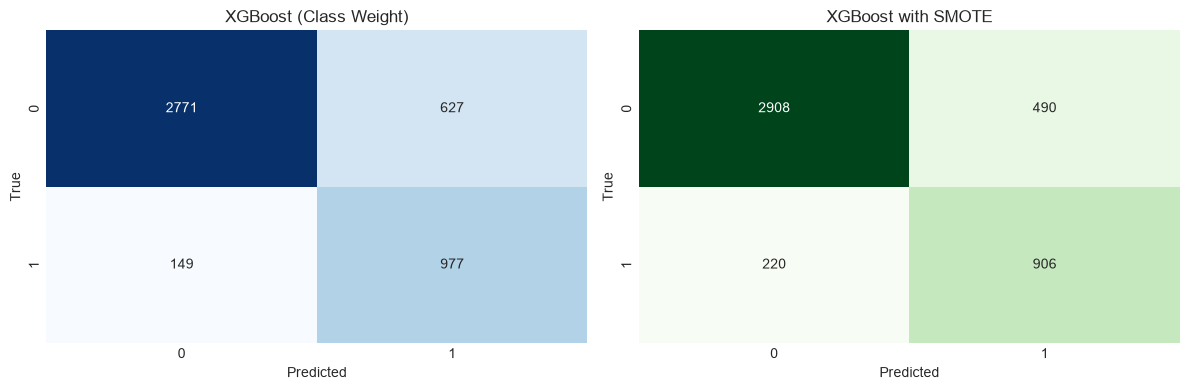

In [22]:
# Confusion Matrix comparison
fig, axes = plt.subplots(1,2, figsize= (12,4))

# Original XGBoost
cm_xgb = confusion_matrix(y_val, y_xgb_pred)
sns.heatmap(cm_xgb, annot = True, fmt = 'd', cmap = 'Blues', ax = axes[0], cbar = False)
axes[0].set_title('XGBoost (Class Weight)')
axes[0].set_ylabel('True')
axes[0].set_xlabel('Predicted')

# XGBoost with SMOTE
cm_xgb_smote = confusion_matrix(y_val, y_xgb_smote_pred)
sns.heatmap(cm_xgb_smote, annot = True, fmt = 'd', cmap = 'Greens', ax = axes[1], cbar = False)
axes[1].set_title('XGBoost with SMOTE')
axes[1].set_ylabel('True')
axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.show()

## Final Model Evaluation and Production Readiness

In [23]:
# Select best model for final evaluation
best_model = xgb_smote  # XGBoost with SMOTE performed best

# Test set evaluation
y_test_pred = xgb_smote.predict(X_test)
y_test_proba = xgb_smote.predict_proba(X_test)[:,1]

test_metrics = {
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision': precision_score(y_test, y_test_pred),
    'Recall': recall_score(y_test, y_test_pred),
    'F1-Score': f1_score(y_test, y_test_pred),
    'ROC-AUC': roc_auc_score(y_test, y_test_proba)
}

print("=== Final Test set Evaluation ===")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

=== Final Test set Evaluation ===
Accuracy: 0.8431
Precision: 0.6548
Recall: 0.7815
F1-Score: 0.7126
ROC-AUC: 0.9157


In [24]:
# Detailed Classification Report
print("\n=== Classification Report ===")
print(classification_report(y_test, y_test_pred, target_names = ['Income ≤50K', 'Income >50K']))


=== Classification Report ===
              precision    recall  f1-score   support

 Income ≤50K       0.92      0.86      0.89      3399
 Income >50K       0.65      0.78      0.71      1126

    accuracy                           0.84      4525
   macro avg       0.79      0.82      0.80      4525
weighted avg       0.86      0.84      0.85      4525



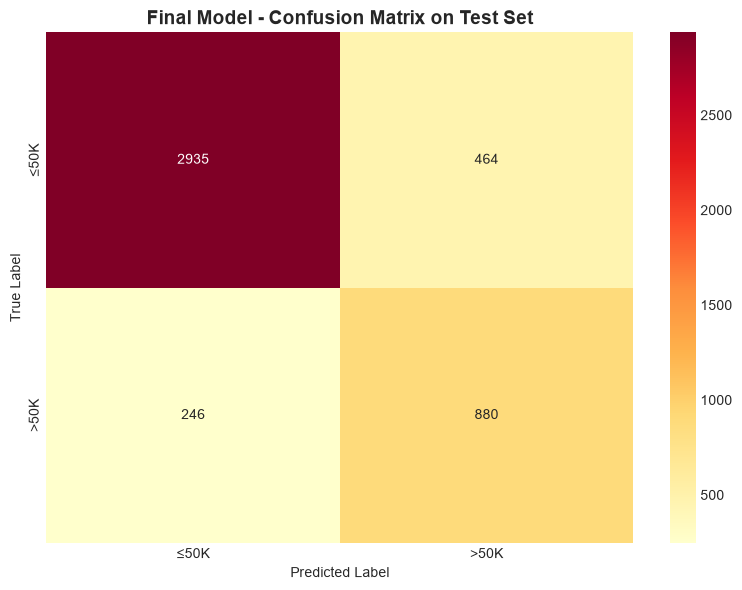


True Negatives: 2935
False Positives: 464
False Negatives: 246
True Positives: 880


In [25]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize = (8,6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'YlOrRd', cbar = True, xticklabels = ['≤50K', '>50K'], yticklabels = ['≤50K', '>50K'])
plt.title('Final Model - Confusion Matrix on Test Set', fontsize = 14, fontweight = 'bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

print(f'\nTrue Negatives: {cm[0,0]}')
print(f'False Positives: {cm[0,1]}')
print(f'False Negatives: {cm[1,0]}')
print(f'True Positives: {cm[1,1]}')

In [26]:
# Save Model and preprocessor
print('Saving model and preprocessor...')
joblib.dump(best_model, 'income_classifier_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(label_encoders, 'label_encoders.pkl')

print('\nModel saved successfully!')
print("Files created:")
print("  - income_classifier_model.pkl")
print("  - scaler.pkl")
print("  - label_encoders.pkl")

Saving model and preprocessor...

Model saved successfully!
Files created:
  - income_classifier_model.pkl
  - scaler.pkl
  - label_encoders.pkl


In [27]:
# Model Card
model_card = f"""
# Income Classification Model Card

## Model Overview
- **Algorithm**: XGBoost with SMOTE
- **Task**: Binary Classification (Income >50K prediction)
- **Training Date**: 2026

## Model Performance
- **Test Accuracy**: {test_metrics['Accuracy']:.4f}
- **Test Precision**: {test_metrics['Precision']:.4f}
- **Test Recall**: {test_metrics['Recall']:.4f}
- **Test F1-Score**: {test_metrics['F1-Score']:.4f}
- **ROC-AUC**: {test_metrics['ROC-AUC']:.4f}

## Features Used
- Age, Workclass, Education, arital Status
- Occupation, Relationship, Race, Sex
- Capital Gain/Loss, Hours per Week
- Native Country

## Preprocessing
- Categorical Encoding: Label Encoding
- Numerical Scaling: StandardScaler
- Imbalance Handling: SMOTE (Synthetic Minority Over-Sampling)

## Known Limitations
- Dataset is from 1994, may not reflect current income distribution
- Geographic Bias based on native country istribution
- Does not capture dynamic career progression

## Production Considerations
- Monitor model performance on new data (data drift)
- Retrain monthly with new data
- Log all predictions for auditing
- Implement fairness checks for protected attributes
"""

print(model_card)

# Save to file
with open('model_card.md', 'w') as f:
    f.write(model_card)
print("\nModel Card saved to model_card.md")


# Income Classification Model Card

## Model Overview
- **Algorithm**: XGBoost with SMOTE
- **Task**: Binary Classification (Income >50K prediction)
- **Training Date**: 2026

## Model Performance
- **Test Accuracy**: 0.8431
- **Test Precision**: 0.6548
- **Test Recall**: 0.7815
- **Test F1-Score**: 0.7126
- **ROC-AUC**: 0.9157

## Features Used
- Age, Workclass, Education, arital Status
- Occupation, Relationship, Race, Sex
- Capital Gain/Loss, Hours per Week
- Native Country

## Preprocessing
- Categorical Encoding: Label Encoding
- Numerical Scaling: StandardScaler
- Imbalance Handling: SMOTE (Synthetic Minority Over-Sampling)

## Known Limitations
- Dataset is from 1994, may not reflect current income distribution
- Geographic Bias based on native country istribution
- Does not capture dynamic career progression

## Production Considerations
- Monitor model performance on new data (data drift)
- Retrain monthly with new data
- Log all predictions for auditing
- Implement fairness 

## Key Insights

1. **Model Selection**
   - XGBoost outperformed simpler models due to gradient boosting advantages
   - Ensemble ethods better capture non-linear relationships
  
2. **Imbalance Handling Importance**
   - SMOTE significantly improved minority class recall
   - Better for real-world deployment where missing positive cases is costly
  
3. **Interpretability is Critical**
   - SHAP shows which features drive each prediction
   - Essential for regulatory compliance and debugging

4. **Evaluation Metrics Matter**
   - Different metrics reveal different aspects of performance
   - Choose metrics alligned with business objectives

1. **Why choose SMOTE over other imbalance techniques?**
   - SMOTE creates synthetic samples via interpolation (not duplicates)
   - Prevents overfitting, better than random sampling
   - Maintains diversity in synthetic examples
  
2. **How is the model deployed to production?**
   - Save model & preprocessor with joblib
   - Create API endpoint (FASTAPI) for predictions
   - Monitor for data drift and model degradation
   - Implement A/B testing for new model versions
  
3. **What are SHAP values?**
   - SHAP = SHaply Additive exPlanations
   - Based on game theory (Shaply values)
   - Shows contribution of each feature to prediction
   - Model-agnostic, theoretically sound
  
4. **Handling feature drift in production**
   - Track feature distribution over time
   - Set alerting thresholds using statistical tests (KS test, Wasserstein)
   - Retrain when drift detected
   - Maintain version control of training data
  
5. **Trade-offs in choosing metrics**
   - Accuracy alone is misleading with imbalanced data
   - Precision: Care about False Positives (eg: Spam filter)
   - Recall: Care about False Negatives (eg: Disease detection)
   - F1: Balanced metric, good default
   - ROC-AUC: Threshold-independent, best for ranking